
**ADDED:** This notebook continues after the EDA in `CardProfiler_EDA_repport.ipynb`. Run its cells from top to bottom. Each new code section has an `ADDED` comment explaining the step. The earlier experiments are saved in `CardProfiler_cleaning_before_update.ipynb`.

The goal here is to keep money values in `df_clean`, create a separate transformed clustering dataset, compare K-means and DBSCAN, and give every customer one `cluster_final` value.

In [2]:
# import mlflow
import mlflow.sklearn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV,StratifiedKFold,RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [3]:
RANDOM_STATE = 42

In [4]:
# ADDED: find the project folder whether Jupyter starts in the project or notebooks folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw" / "dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "repport" / "cleaning_notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

numeric_columns = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES",
                   "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
df = pd.read_csv(RAW_FILE)
print("Customers:", len(df))
display(df.head())

Customers: 8950


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763


## Story 2 — Clean reference data

**ADDED:** Keep the seven monetary features in their original units. `CUST_ID` remains here to identify rows, but it will not be used as a clustering feature. The dataset has one missing `CREDIT_LIMIT`, so we fill that value with the column median.

In [5]:
# ADDED: remove duplicate rows, check IDs, and fill only the known missing column.
df_clean = df.drop_duplicates().reset_index(drop=True).copy()
if df_clean["CUST_ID"].duplicated().any():
    raise ValueError("Some CUST_ID values are repeated. Check them before clustering.")
if df_clean[numeric_columns].drop(columns="CREDIT_LIMIT").isna().any().any():
    raise ValueError("A feature other than CREDIT_LIMIT has missing values.")
df_clean["CREDIT_LIMIT"] = df_clean["CREDIT_LIMIT"].fillna(df_clean["CREDIT_LIMIT"].median())
df_clean.to_csv(OUTPUT_DIR / "df_clean.csv", index=False)
print("Clean customers:", len(df_clean))
print("Missing feature values:", int(df_clean[numeric_columns].isna().sum().sum()))

Clean customers: 8950
Missing feature values: 0


In [6]:
# ADDED: make a separate copy for clustering, without the customer ID.
clustering_raw = df_clean[numeric_columns].copy()
if (clustering_raw < 0).any().any():
    raise ValueError("log1p cannot be used on these negative monetary values.")

# ADDED: log1p handles zero amounts and reduces strong right skew.
clustering_log = np.log1p(clustering_raw)
skew_table = pd.DataFrame({
    "before_log": clustering_raw.skew(),
    "after_log": clustering_log.skew(),
})
display(skew_table.round(2))
skew_table.to_csv(OUTPUT_DIR / "skew_before_after.csv")

,before_log,after_log
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
ONEOFF_PURCHASES,10.05,0.19
INSTALLMENTS_PURCHASES,7.30,-0.02
CASH_ADVANCE,5.17,0.26
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78


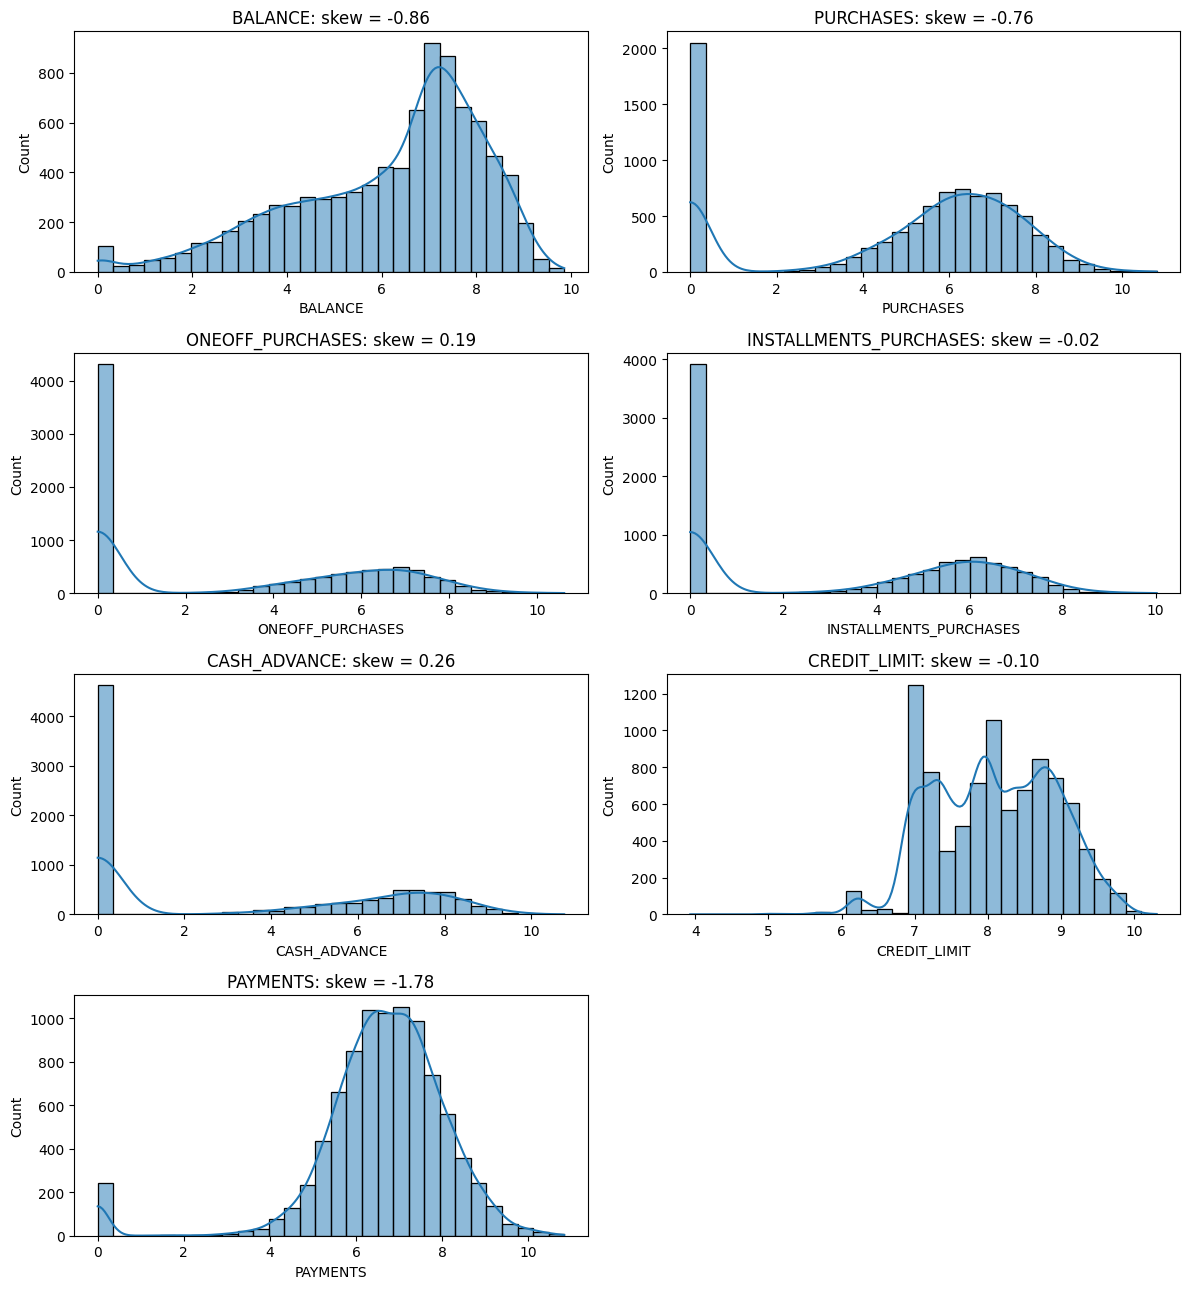

In [7]:
# ADDED: view each distribution after the logarithmic change.
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for axis, column in zip(axes.flat, numeric_columns):
    sns.histplot(clustering_log[column], bins=30, kde=True, ax=axis)
    axis.set_title(f"{column}: skew = {clustering_log[column].skew():.2f}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_after_log.png", dpi=150)
plt.show()

In [8]:
# ADDED: standardize AFTER log so large monetary units do not dominate PCA.
scaler = StandardScaler()
scaled_values = scaler.fit_transform(clustering_log)
df_prepare_clustering = pd.DataFrame(scaled_values, columns=numeric_columns)
if not np.isfinite(scaled_values).all():
    raise ValueError("The clustering data contains NaN or infinity.")
df_prepare_clustering.to_csv(OUTPUT_DIR / "df_prepare_clustering.csv", index=False)
display(df_prepare_clustering.head())

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,-1.205218,-0.113532,-0.987090,0.394480,-0.930733,-1.447163,-0.824484
1,0.948918,-1.679855,-0.987090,-1.087454,1.528788,0.926060,1.065033
2,0.824993,0.600727,1.062022,-1.087454,-0.930733,1.010229,-0.119300
3,0.624653,0.827499,1.265778,-1.087454,0.564372,1.010229,-4.161996
4,0.271260,-0.708481,-0.114307,-1.087454,-0.930733,-1.224909,-0.064979


,components,explained_variance,cumulative_variance
0,1,0.354,0.354
1,2,0.293,0.646
2,3,0.114,0.760
3,4,0.100,0.860
4,5,0.076,0.937
5,6,0.050,0.986
6,7,0.014,1.000


First component count reaching 80%: 4


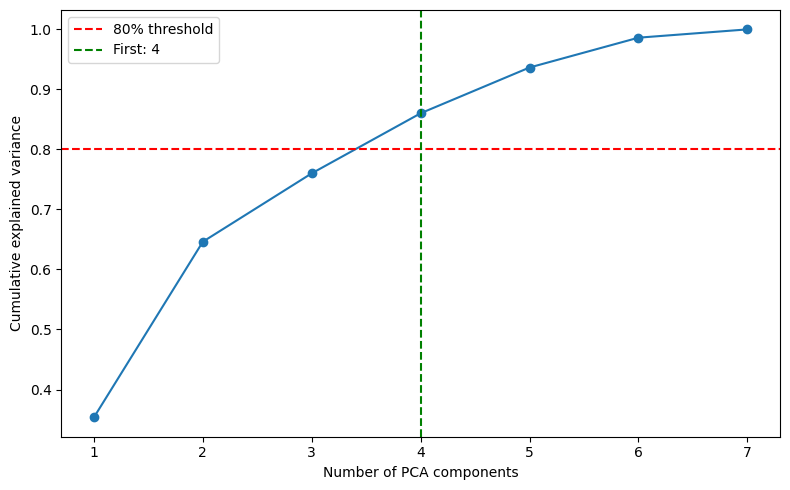

In [9]:
# ADDED: first fit PCA with all seven components to inspect explained variance.
full_pca = PCA()
full_pca.fit(scaled_values)
cumulative_variance = np.cumsum(full_pca.explained_variance_ratio_)
first_80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
pca_table = pd.DataFrame({
    "components": range(1, len(cumulative_variance) + 1),
    "explained_variance": full_pca.explained_variance_ratio_,
    "cumulative_variance": cumulative_variance,
})
display(pca_table.round(3))
pca_table.to_csv(OUTPUT_DIR / "pca_variance.csv", index=False)
print("First component count reaching 80%:", first_80)

# ADDED: mark the 80% line on the cumulative PCA curve.
plt.figure(figsize=(8, 5))
plt.plot(pca_table["components"], pca_table["cumulative_variance"], marker="o")
plt.axhline(0.80, color="red", linestyle="--", label="80% threshold")
plt.axvline(first_80, color="green", linestyle="--", label=f"First: {first_80}")
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_pca_variance.png", dpi=150)
plt.show()

## Story 3 — K-means search

**ADDED:** The 80% result is an initial guide, not a fixed choice. We try 2–5 PCA components with 2–7 clusters. For each pair we record inertia, silhouette, and cluster sizes. Silhouette uses a fixed sample of 1,000 customers so the notebook finishes in a reasonable time.

In [10]:
# ADDED: try every PCA count together with every k value.
pca_data = {}
kmeans_models = {}
kmeans_rows = []
for components in range(2, 6):
    pca_data[components] = PCA(n_components=components).fit_transform(scaled_values)
    for k in range(2, 8):
        model = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = model.fit_predict(pca_data[components])
        counts = pd.Series(labels).value_counts()
        silhouette = silhouette_score(
            pca_data[components], labels, sample_size=1000, random_state=42
        )
        kmeans_rows.append({
            "components": components,
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette,
            "smallest_cluster_pct": counts.min() / len(labels) * 100,
            "largest_cluster_pct": counts.max() / len(labels) * 100,
            "davies_bouldin": davies_bouldin_score(pca_data[components], labels),
            "calinski_harabasz": calinski_harabasz_score(pca_data[components], labels),
        })
        kmeans_models[(components, k)] = model

kmeans_table = pd.DataFrame(kmeans_rows)
kmeans_table.to_csv(OUTPUT_DIR / "kmeans_grid.csv", index=False)
display(kmeans_table.round(3))

,components,k,inertia,silhouette,smallest_cluster_pct,largest_cluster_pct,davies_bouldin,calinski_harabasz
0,2,2,23546.232,0.446,31.296,68.704,0.926,6437.513
1,2,3,13250.771,0.450,27.151,37.799,0.774,9195.099
2,2,4,10420.610,0.423,19.821,31.274,0.879,8603.863
3,2,5,8247.579,0.405,15.620,27.743,0.818,8741.307
4,2,6,6687.617,0.387,11.911,27.106,0.806,9040.519
5,2,7,5637.302,0.394,10.849,19.844,0.795,9214.236
6,3,2,30684.842,0.381,31.397,68.603,1.084,4940.180
7,3,3,20211.665,0.381,26.726,39.899,1.004,6067.708
8,3,4,16455.108,0.380,20.916,27.832,1.038,5648.801
9,3,5,13787.086,0.383,15.732,24.201,1.004,5488.627


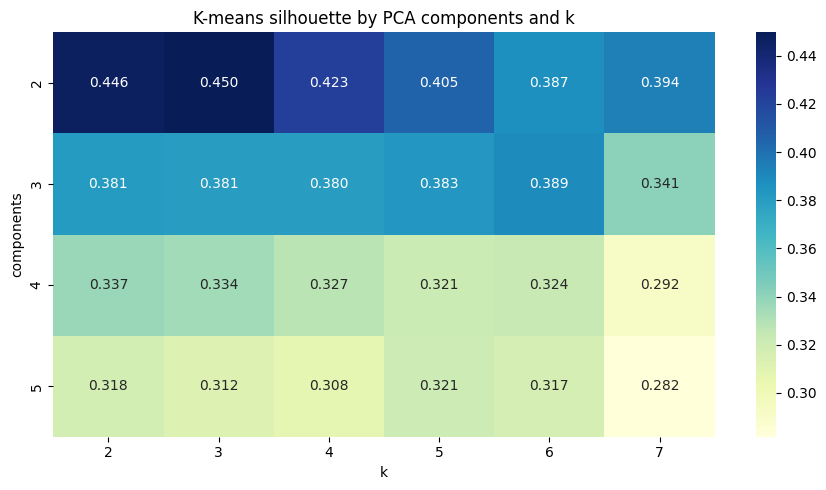

In [11]:
# ADDED: show the PCA-components x k silhouette heatmap requested in the brief.
heatmap_data = kmeans_table.pivot(index="components", columns="k", values="silhouette")
plt.figure(figsize=(9, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("K-means silhouette by PCA components and k")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_kmeans_heatmap.png", dpi=150)
plt.show()

In [12]:
# ADDED: keep only K-means choices with no group under 10% or over 90%.
balanced_kmeans = kmeans_table[
    (kmeans_table["smallest_cluster_pct"] >= 10)
    & (kmeans_table["largest_cluster_pct"] <= 90)
]
if balanced_kmeans.empty:
    raise ValueError("No balanced K-means result was found. Review the grid.")
best_kmeans = balanced_kmeans.sort_values("silhouette", ascending=False).iloc[0]
best_components = int(best_kmeans["components"])
best_k = int(best_kmeans["k"])
best_kmeans_model = kmeans_models[(best_components, best_k)]
df_clean["cluster_kmeans"] = best_kmeans_model.labels_
print("Selected PCA components:", best_components)
print("Selected k:", best_k)
print("Silhouette:", round(best_kmeans["silhouette"], 3))

# ADDED: report how many customers belong to each selected K-means cluster.
kmeans_sizes = df_clean["cluster_kmeans"].value_counts().sort_index()
kmeans_size_table = pd.DataFrame({
    "cluster": kmeans_sizes.index,
    "customers": kmeans_sizes.values,
    "percent": kmeans_sizes.values / len(df_clean) * 100,
})
display(kmeans_size_table.round(2))
kmeans_size_table.to_csv(OUTPUT_DIR / "kmeans_cluster_sizes.csv", index=False)

Selected PCA components: 2
Selected k: 3
Silhouette: 0.45


,cluster,customers,percent
0,0,3383,37.80
1,1,2430,27.15
2,2,3137,35.05


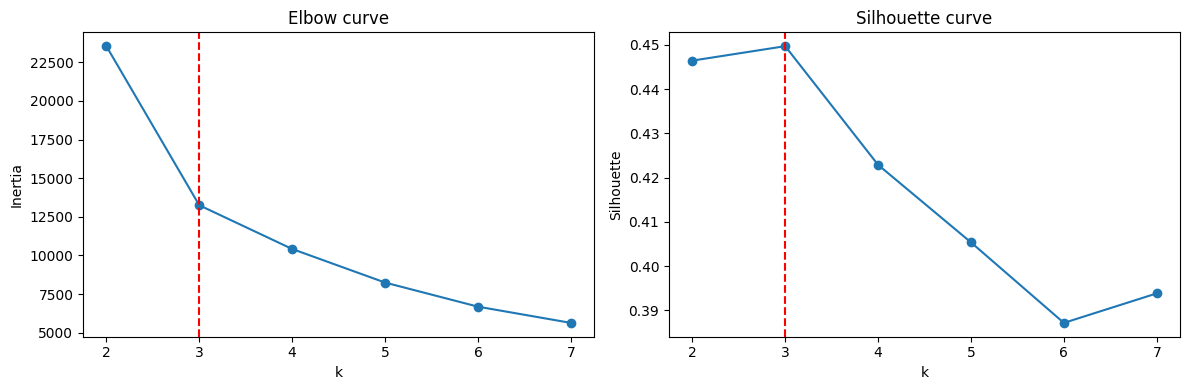

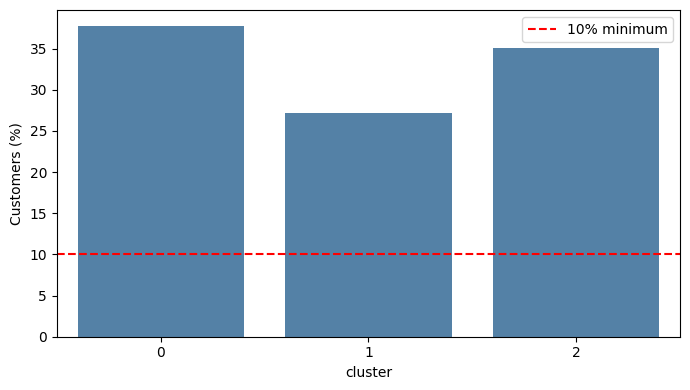

In [13]:
# ADDED: use the chosen PCA count for the elbow and silhouette curves.
curve = kmeans_table[kmeans_table["components"] == best_components].sort_values("k")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(curve["k"], curve["inertia"], marker="o")
axes[0].set(title="Elbow curve", xlabel="k", ylabel="Inertia")
axes[1].plot(curve["k"], curve["silhouette"], marker="o")
axes[1].set(title="Silhouette curve", xlabel="k", ylabel="Silhouette")
for axis in axes:
    axis.axvline(best_k, color="red", linestyle="--")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_kmeans_curves.png", dpi=150)
plt.show()

# ADDED: the dashed line shows the brief's approximate 10% size limit.
plt.figure(figsize=(7, 4))
sns.barplot(data=kmeans_size_table, x="cluster", y="percent", color="steelblue")
plt.axhline(10, color="red", linestyle="--", label="10% minimum")
plt.ylabel("Customers (%)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_kmeans_sizes.png", dpi=150)
plt.show()

## Story 3 — DBSCAN search

**ADDED:** DBSCAN can label unusual customers as `-1` (noise). We try several values of PCA components, `eps`, and `min_samples`. We score the classified customers and report the noise percentage separately; a high silhouette score is not enough if most customers fall into one group.

In [14]:
# ADDED: test a small, readable DBSCAN grid on each PCA version.
dbscan_rows = []
dbscan_labels = {}
for components in range(2, 6):
    for eps in [0.4, 0.6, 0.8, 1.0, 1.2]:
        for min_samples in [5, 10]:
            labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(
                pca_data[components]
            )
            noise_pct = (labels == -1).mean() * 100
            keep = labels != -1
            x_classified = pca_data[components][keep]
            labels_classified = labels[keep]
            counts = pd.Series(labels_classified).value_counts()
            number_of_clusters = len(counts)

            # ADDED: metrics need at least two real clusters to be meaningful.
            if 2 <= number_of_clusters < len(labels_classified):
                silhouette = silhouette_score(
                    x_classified, labels_classified,
                    sample_size=min(1000, len(labels_classified)), random_state=42
                )
                davies = davies_bouldin_score(x_classified, labels_classified)
                calinski = calinski_harabasz_score(x_classified, labels_classified)
                smallest_pct = counts.min() / len(labels_classified) * 100
                largest_pct = counts.max() / len(labels_classified) * 100
            else:
                silhouette = np.nan
                davies = np.nan
                calinski = np.nan
                smallest_pct = np.nan
                largest_pct = np.nan

            dbscan_rows.append({
                "components": components,
                "eps": eps,
                "min_samples": min_samples,
                "n_clusters": number_of_clusters,
                "silhouette": silhouette,
                "noise_pct": noise_pct,
                "davies_bouldin": davies,
                "calinski_harabasz": calinski,
                "smallest_cluster_pct": smallest_pct,
                "largest_cluster_pct": largest_pct,
            })
            dbscan_labels[(components, eps, min_samples)] = labels

dbscan_table = pd.DataFrame(dbscan_rows).sort_values("silhouette", ascending=False)
dbscan_table.to_csv(OUTPUT_DIR / "dbscan_grid_ranked.csv", index=False)
display(dbscan_table.head(10).round(3))

,components,eps,min_samples,n_clusters,silhouette,noise_pct,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
38,5,1.2,5,3,0.361,0.223,0.871,126.000,0.067,99.104
11,3,0.4,10,5,0.331,2.827,0.650,1440.140,0.149,75.992
33,5,0.6,10,7,0.330,8.559,0.974,1967.918,0.098,31.109
35,5,0.8,10,5,0.309,3.106,0.799,1148.187,0.115,76.176
37,5,1.0,10,5,0.307,1.017,0.894,189.245,0.113,97.844
23,4,0.6,10,4,0.303,3.642,0.774,1569.765,0.510,76.276
25,4,0.8,10,3,0.301,1.162,0.790,58.931,0.192,99.559
39,5,1.2,10,5,0.298,0.391,0.980,214.384,0.146,97.521
36,5,1.0,5,5,0.297,0.704,0.974,201.142,0.158,97.693
34,5,0.8,5,10,0.281,1.609,0.784,555.070,0.057,75.562


In [15]:
# ADDED: attach the top valid DBSCAN result and mark its noise points.
valid_dbscan = dbscan_table.dropna(subset=["silhouette"])
if valid_dbscan.empty:
    raise ValueError("DBSCAN did not find two real clusters in the search grid.")
best_dbscan = valid_dbscan.iloc[0]
db_components = int(best_dbscan["components"])
db_eps = float(best_dbscan["eps"])
db_min_samples = int(best_dbscan["min_samples"])
df_clean["cluster_dbscan"] = dbscan_labels[(db_components, db_eps, db_min_samples)]
df_clean["est_atypique_dbscan"] = df_clean["cluster_dbscan"] == -1

# ADDED: compare separation, noise coverage, and cluster balance in one table.
comparison = pd.DataFrame([
    {
        "method": "K-means", "components": best_components, "parameters": f"k={best_k}",
        "silhouette": best_kmeans["silhouette"], "noise_pct": 0,
        "davies_bouldin": best_kmeans["davies_bouldin"],
        "calinski_harabasz": best_kmeans["calinski_harabasz"],
        "smallest_cluster_pct": best_kmeans["smallest_cluster_pct"],
        "largest_cluster_pct": best_kmeans["largest_cluster_pct"],
    },
    {
        "method": "DBSCAN", "components": db_components,
        "parameters": f"eps={db_eps}, min_samples={db_min_samples}",
        "silhouette": best_dbscan["silhouette"], "noise_pct": best_dbscan["noise_pct"],
        "davies_bouldin": best_dbscan["davies_bouldin"],
        "calinski_harabasz": best_dbscan["calinski_harabasz"],
        "smallest_cluster_pct": best_dbscan["smallest_cluster_pct"],
        "largest_cluster_pct": best_dbscan["largest_cluster_pct"],
    },
])
display(comparison.round(3))
comparison.to_csv(OUTPUT_DIR / "clustering_comparison.csv", index=False)

,method,components,parameters,silhouette,noise_pct,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
0,K-means,2,k=3,0.450,0.000,0.774,9195.099,27.151,37.799
1,DBSCAN,5,"eps=1.2, min_samples=5",0.361,0.223,0.871,126.000,0.067,99.104


In [16]:
# ADDED: choose one method and make sure every customer receives a final label.
# We use DBSCAN only if it has zero noise, balanced groups, and a silhouette
# score at least 0.05 higher than K-means. Otherwise K-means is safer here.
dbscan_wins = (
    best_dbscan["noise_pct"] == 0
    and best_dbscan["smallest_cluster_pct"] >= 10
    and best_dbscan["largest_cluster_pct"] <= 90
    and best_dbscan["silhouette"] >= best_kmeans["silhouette"] + 0.05
)
if dbscan_wins:
    final_method = "DBSCAN"
    final_components = db_components
    df_clean["cluster_final"] = df_clean["cluster_dbscan"]
else:
    final_method = "K-means"
    final_components = best_components
    df_clean["cluster_final"] = df_clean["cluster_kmeans"]

if df_clean["cluster_final"].isna().any() or (df_clean["cluster_final"] == -1).any():
    raise ValueError("Some customers have no final cluster.")
df_clean.to_csv(OUTPUT_DIR / "df_clean_with_clusters.csv", index=False)
print("Final method:", final_method)
print("Customers with a final cluster:", df_clean["cluster_final"].notna().sum())
display(df_clean[["CUST_ID", "cluster_kmeans", "cluster_dbscan",
                  "est_atypique_dbscan", "cluster_final"]].head())

Final method: K-means
Customers with a final cluster: 8950


,CUST_ID,cluster_kmeans,cluster_dbscan,est_atypique_dbscan,cluster_final
0,C10001,2,0,False,2
1,C10002,1,0,False,1
2,C10003,0,0,False,0
3,C10004,2,1,False,2
4,C10005,2,0,False,2


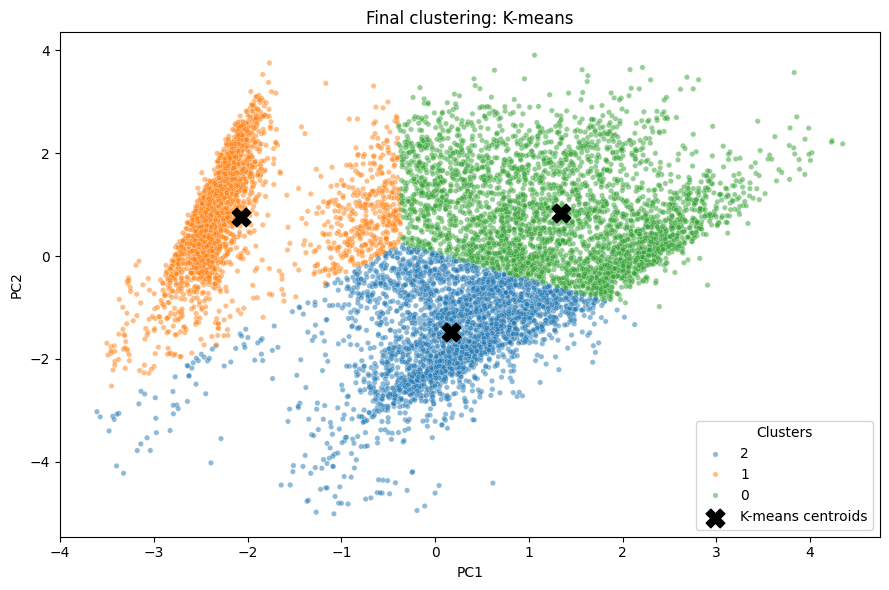

In [17]:
# ADDED: show the final labels on the first two PCA axes.
final_pca = pca_data[final_components]
plot_data = pd.DataFrame({
    "PC1": final_pca[:, 0],
    "PC2": final_pca[:, 1],
    "cluster_final": df_clean["cluster_final"].astype(str),
})
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="cluster_final", s=15, alpha=0.5)
if final_method == "K-means":
    centers = best_kmeans_model.cluster_centers_
    plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=180,
                c="black", label="K-means centroids")
    plt.legend(title="Clusters")
plt.title(f"Final clustering: {final_method}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_final_clusters.png", dpi=151)
plt.show()

In [18]:
# ADDED: save a short explanation of the selected model for your report.
summary = (
    f"PCA reaches 80% explained variance with {first_80} components.\n"
    f"K-means: {best_components} components, k={best_k}, "
    f"silhouette={best_kmeans['silhouette']:.3f}, "
    f"smallest group={best_kmeans['smallest_cluster_pct']:.1f}%.\n"
    f"DBSCAN: {db_components} components, eps={db_eps}, "
    f"min_samples={db_min_samples}, silhouette={best_dbscan['silhouette']:.3f}, "
    f"noise={best_dbscan['noise_pct']:.1f}%, "
    f"largest group={best_dbscan['largest_cluster_pct']:.1f}%.\n"
    f"Final method: {final_method}. Every customer has cluster_final.\n"
    "Silhouette is measured on a fixed sample of up to 1000 customers. "
    "DBSCAN metrics exclude noise, and the noise rate is shown separately.\n"
)
(OUTPUT_DIR / "clustering_summary.txt").write_text(summary, encoding="utf-8")
print(summary)

PCA reaches 80% explained variance with 4 components.
K-means: 2 components, k=3, silhouette=0.450, smallest group=27.2%.
DBSCAN: 5 components, eps=1.2, min_samples=5, silhouette=0.361, noise=0.2%, largest group=99.1%.
Final method: K-means. Every customer has cluster_final.
Silhouette is measured on a fixed sample of up to 1000 customers. DBSCAN metrics exclude noise, and the noise rate is shown separately.



| Measure | K-means | DBSCAN |
|---|---:|---:|
| Silhouette score | **0.450** | 0.361 |
| Smallest cluster | **27.2%** | 0.1% |
| Largest cluster | **37.8%** | 99.1% |
| Unassigned points (noise) | **0%** | 0.2% |
K-means separates the customers better and gives three reasonably balanced groups. DBSCAN puts almost everyone in one group, so its result is not useful for customer segmentation. K-means also assigns every customer a cluster,

## Feature Story 4 — Cluster interpretation and target creation


# standardized_profile

In [19]:
profile_data = df_prepare_clustering.copy()
profile_data["cluster_final"] = df_clean["cluster_final"].to_numpy()
standardized_profile = profile_data.groupby("cluster_final").mean()

display(standardized_profile.round(2))

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
cluster_final,,,,,,,
0,0.46,0.78,0.87,0.48,-0.02,0.60,0.57
1,0.49,-1.40,-0.80,-1.02,1.00,-0.12,-0.01
2,-0.87,0.24,-0.33,0.28,-0.75,-0.56,-0.61


In [20]:
df_clean.columns

Index(['CUST_ID', 'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS',
       'cluster_kmeans', 'cluster_dbscan', 'est_atypique_dbscan',
       'cluster_final'],
      dtype='str')

In [21]:

behavioral_features = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS",
]

real_profile_data = df_clean[behavioral_features + ["cluster_final"]].copy()
real_profile = real_profile_data.groupby("cluster_final")[behavioral_features].mean()
real_median_profile = real_profile_data.groupby("cluster_final")[behavioral_features].median()

display(real_profile.round(2))
print("Real-profile clusters:", real_profile.index.tolist())
print("Standardized-profile clusters:", standardized_profile.index.tolist())
print("All profile values present:", not real_profile.isna().any().any())


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
cluster_final,,,,,,,
0,2266.79,2203.38,1414.47,789.14,1096.99,6531.34,2893.90
1,2174.73,23.79,19.03,4.81,2007.25,3980.96,1629.68
2,334.37,467.60,150.12,318.04,54.87,2695.12,561.51


Real-profile clusters: [0, 1, 2]
Standardized-profile clusters: [0, 1, 2]
All profile values present: True


In [22]:
cluster_mapping = {
    0: "High-purchase, higher-limit customers",
    1: "Cash-advance, low-purchase customers",
    2: "Lower-balance, lower-cash-advance customers",
}

mapped_clusters = set(cluster_mapping)


df_clean["target"] = df_clean["cluster_final"].map(cluster_mapping)
if df_clean["target"].isna().any():
    raise ValueError("Some customers did not receive a target label.")

# Confirm that mapping names preserve the original cluster proportions exactly.
cluster_proportions = df_clean["cluster_final"].value_counts(normalize=True).sort_index()
cluster_counts = df_clean["cluster_final"].value_counts().sort_index()
target_counts_by_name = df_clean["target"].value_counts().reindex(
    [cluster_mapping[c] for c in sorted(cluster_mapping)]
)
target_proportions = target_counts_by_name / len(df_clean)
if not np.array_equal(cluster_counts.to_numpy(), target_counts_by_name.to_numpy()):
    raise ValueError("Target counts do not match the original cluster counts.")

print("Missing targets:", int(df_clean["target"].isna().sum()))
display(pd.DataFrame({
    "customers": cluster_counts,
    "target_name": pd.Series(cluster_mapping),
    "cluster_pct": (cluster_proportions * 100).round(2),
    "target_pct": (target_proportions.to_numpy() * 100).round(2),
}, index=cluster_counts.index))


Missing targets: 0


,customers,target_name,cluster_pct,target_pct
cluster_final,,,,
0,3383,"High-purchase, higher-limit customers",37.80,37.80
1,2430,"Cash-advance, low-purchase customers",27.15,27.15
2,3137,"Lower-balance, lower-cash-advance customers",35.05,35.05


### Segment descriptions

**Cluster 0 — High-purchase, higher-limit customers.** The standardized profile is positive for purchases, one-off purchases, credit limit, and payments. In original units, this group has the highest mean purchases (2,203), one-off purchases (1,414), credit limit (6,531), and payments (2,894) among the three groups. This name describes relative behavior in this run; it does not imply a bank-defined “premium” status.

**Cluster 1 — Cash-advance, low-purchase customers.** Its standardized purchase and installment-purchase means are strongly negative while cash advance is positive. The real-value means show purchases of 24 and cash advances of 2,007, which supports describing the group as cash-advance-oriented with very little purchase activity.

**Cluster 2 — Lower-balance, lower-cash-advance customers.** Its standardized means are negative for balance, cash advance, credit limit, and payments, while installment purchases are slightly positive. In original units, its mean balance (334) and cash advance (55) are the lowest of the three groups. The name is intentionally comparative; it does not claim these customers have no activity.


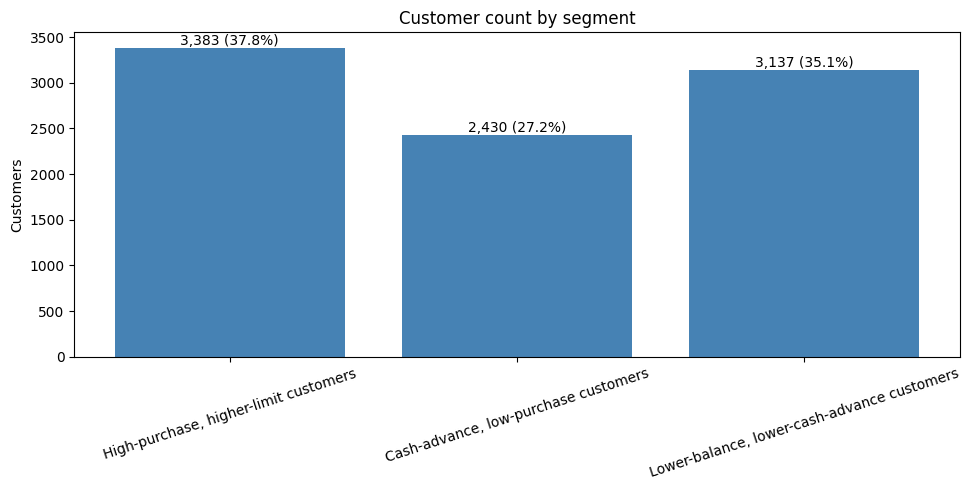

In [23]:
target_order = [cluster_mapping[c] for c in sorted(cluster_mapping)]
target_counts = df_clean["target"].value_counts().reindex(target_order)
target_pct = target_counts / len(df_clean) * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(target_counts.index, target_counts.values, color="steelblue")
ax.set_title("Customer count by segment")
ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=18)
for bar, pct in zip(bars, target_pct):
    ax.annotate(f"{int(bar.get_height()):,} ({pct:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_segment_sizes.png", dpi=150)
plt.show()


,CASH_ADVANCE,PURCHASES,PAYMENTS
target,,,
"High-purchase, higher-limit customers",0.00,1365.50,1791.29
"Cash-advance, low-purchase customers",1270.57,0.00,767.02
"Lower-balance, lower-cash-advance customers",0.00,325.95,394.14


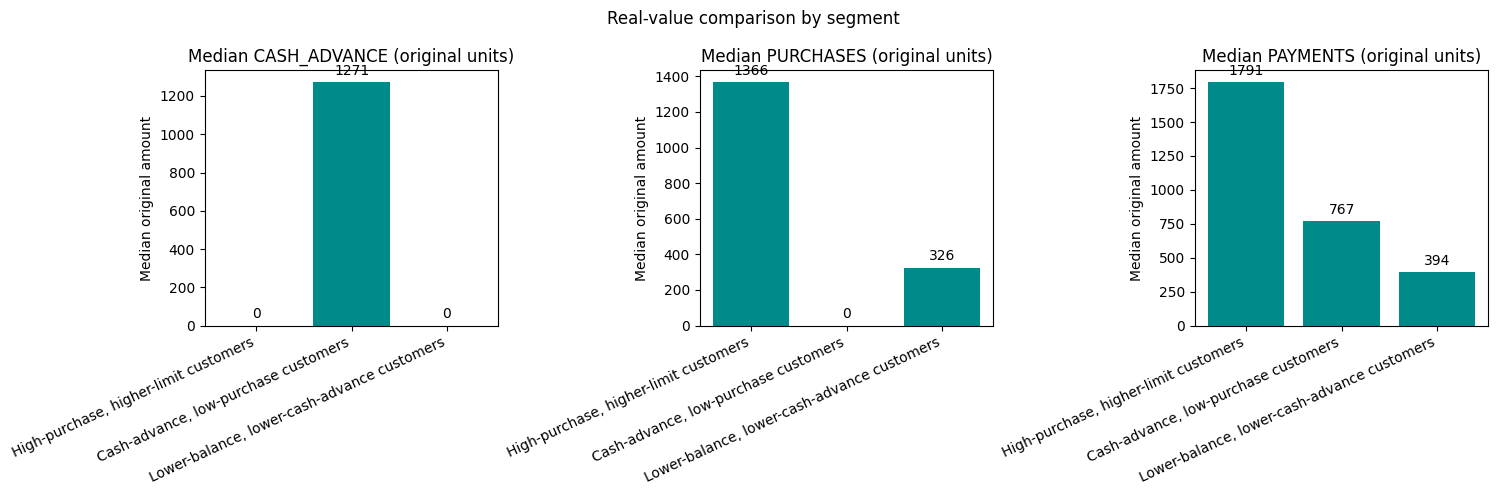

In [24]:
key_features = ["CASH_ADVANCE", "PURCHASES", "PAYMENTS"]
real_median_by_target = (
    df_clean.groupby("target")[key_features].median().reindex(target_order)
)
display(real_median_by_target.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, feature in zip(axes, key_features):
    values = real_median_by_target[feature]
    bars = ax.bar(range(len(values)), values.values, color="darkcyan")
    ax.set_xticks(range(len(values)), values.index, rotation=25, ha="right")
    ax.set_title(f"Median {feature} (original units)")
    ax.set_ylabel("Median original amount")
    ax.bar_label(bars, fmt="%.0f", padding=3)
fig.suptitle("Real-value comparison by segment")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_key_feature_comparison.png", dpi=150)
plt.show()


## Feature Story 5 : Classification supervisée et évaluation des modèles

In [25]:
from sklearn.model_selection import train_test_split
def splite_y_x(dataset)->tuple:
    X = dataset[behavioral_features]
    Y = dataset["target"]
    return train_test_split(X,Y,random_state=RANDOM_STATE,stratify=Y,test_size=0.2)
x_train,x_test,y_train,y_test = splite_y_x(df_clean)

In [26]:
models = [
    (
        "logisticRegression",
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        [
            {"classifier__C": [0.1, 1, 10],
             "classifier__solver": ["lbfgs"],
             "classifier__l1_ratio": [0.0],
             "classifier__tol": [1e-4]},
            {"classifier__C": [0.1, 1, 10],
             "classifier__solver": ["saga"],
             "classifier__l1_ratio": [0.0, 0.5, 1.0],
             "classifier__tol": [1e-3]},
        ],
    ),
    (
        "DecisionTreeClassifier",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "classifier__max_depth": [3, 6, 10, None],
            "classifier__min_samples_split": [2, 10],
            "classifier__min_samples_leaf": [1, 4],
            "classifier__ccp_alpha": [0.0, 0.001],
            "classifier__criterion": ["gini", "entropy"],
        },
    ),
    (
        "RandomForestClassifier",
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [100, 300],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_split": [2, 10],
            "classifier__min_samples_leaf": [1, 4],
            "classifier__max_features": ["sqrt", None],
        },
    ),
    (
        "SVC",
        SVC(),
        [
            {"classifier__kernel": ["linear"],
             "classifier__C": [0.1, 1, 10],
             "classifier__class_weight": [None, "balanced"]},
            {"classifier__kernel": ["rbf"],
             "classifier__C": [0.1, 1, 10],
             "classifier__gamma": ["scale", 0.01, 0.1],
             "classifier__class_weight": [None, "balanced"]},
        ],
    ),
]

In [27]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [28]:
def start_train(*, models, search_type) -> dict:
    model_results = {}
    for name, classifier, params in models:
        candidate = Pipeline(steps=[
            ("scaler", StandardScaler()),
            ("classifier", classifier),
        ])

        if search_type == "GridSearchCV":
            search = GridSearchCV(
                estimator=candidate,
                param_grid=params,
                scoring="f1_macro",
                cv=cv,
                n_jobs=-1,
                error_score="raise",
            )

        elif search_type == "RandomizedSearchCV":
            search = RandomizedSearchCV(
                estimator=candidate,
                param_distributions=params,
                n_iter=30,
                scoring="f1_macro",
                cv=cv,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                error_score="raise",
            )

        else:
            raise ValueError(f"Unknown search_type: {search_type}")

        search.fit(x_train, y_train)
        model_results[name] = {
            "pipeline": search.best_estimator_,
            "cv_f1_macro": search.best_score_,
            "best_params": search.best_params_,
        }

    return model_results

In [29]:
model_results = start_train(models=models, search_type="GridSearchCV")

KeyboardInterrupt: 

In [ ]:
cv_summary = pd.DataFrame([
    {"model": name, "cv_f1_macro": result["cv_f1_macro"],
     "best_params": result["best_params"]}
    for name, result in model_results.items()
]).sort_values("cv_f1_macro", ascending=False)
display(cv_summary)


,model,cv_f1_macro,best_params
2,RandomForestClassifier,0.967164,"{'classifier__max_depth': None, 'classifier__m..."
1,DecisionTreeClassifier,0.941062,"{'classifier__ccp_alpha': 0.0, 'classifier__cr..."
3,SVC,0.941001,"{'classifier__C': 10, 'classifier__class_weigh..."
0,logisticRegression,0.911680,"{'classifier__C': 10, 'classifier__l1_ratio': ..."


### Evaluate the tuned models on the held-out test set

The model choice remains based on `cv_f1_macro` from the training folds. The test tables describe how each fitted Pipeline performs on unseen rows. Use `sort_by` to reorder the comparison table by a metric; use `focus_class` to inspect one segment. Neither option changes the CV-selected model.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix


def evaluate_models(model_results, x_test, y_test, focus_class=None,
                    sort_by="cv_f1_macro"):
    if not model_results:
        raise ValueError("model_results is empty. Run the training cell first.")

    allowed_sort = {
        "cv_f1_macro", "test_accuracy", "test_precision_macro",
        "test_recall_macro", "test_f1_macro",
    }
    if sort_by not in allowed_sort:
        raise ValueError(f"sort_by must be one of {sorted(allowed_sort)}")

    labels = sorted(y_test.unique())
    if focus_class is not None and focus_class not in labels:
        raise ValueError(f"Unknown focus_class: {focus_class}")

    overall_rows = []
    class_rows = []
    confusion_matrices = {}

    for name, result in model_results.items():
        y_pred = result["pipeline"].predict(x_test)
        report = classification_report(
            y_test, y_pred, labels=labels, output_dict=True, zero_division=0
        )
        overall_rows.append({
            "model": name,
            "cv_f1_macro": result["cv_f1_macro"],
            "test_accuracy": report["accuracy"],
            "test_precision_macro": report["macro avg"]["precision"],
            "test_recall_macro": report["macro avg"]["recall"],
            "test_f1_macro": report["macro avg"]["f1-score"],
        })
        for label in labels:
            class_rows.append({
                "model": name,
                "segment": label,
                "precision": report[label]["precision"],
                "recall": report[label]["recall"],
                "f1": report[label]["f1-score"],
                "support": int(report[label]["support"]),
            })
        confusion_matrices[name] = pd.DataFrame(
            confusion_matrix(y_test, y_pred, labels=labels),
            index=pd.Index(labels, name="actual"),
            columns=pd.Index(labels, name="predicted"),
        )

    summary = pd.DataFrame(overall_rows)
    cv_best_model = summary.loc[summary["cv_f1_macro"].idxmax(), "model"]
    summary = summary.sort_values(sort_by, ascending=False).reset_index(drop=True)
    per_class = pd.DataFrame(class_rows)
    focused = None if focus_class is None else per_class[
        per_class["segment"] == focus_class
    ].reset_index(drop=True)
    return {
        "summary": summary,
        "per_class": per_class,
        "focus_class": focused,
        "confusion_matrices": confusion_matrices,
        "cv_best_model": cv_best_model,
    }


In [ ]:
evaluation = evaluate_models(model_results, x_test, y_test, sort_by="cv_f1_macro")
display(evaluation["summary"].round(3))
display(evaluation["per_class"].round(3))
print("CV-selected model:", evaluation["cv_best_model"])
display(evaluation["confusion_matrices"][evaluation["cv_best_model"]])


,model,cv_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,RandomForestClassifier,0.967,0.968,0.969,0.968,0.968
1,DecisionTreeClassifier,0.941,0.948,0.950,0.948,0.949
2,SVC,0.941,0.930,0.929,0.932,0.930
3,logisticRegression,0.912,0.904,0.905,0.907,0.906


,model,segment,precision,recall,f1,support
0,logisticRegression,"Cash-advance, low-purchase customers",0.915,0.934,0.925,486
1,logisticRegression,"High-purchase, higher-limit customers",0.928,0.877,0.902,677
2,logisticRegression,"Lower-balance, lower-cash-advance customers",0.872,0.909,0.890,627
3,DecisionTreeClassifier,"Cash-advance, low-purchase customers",0.973,0.955,0.964,486
4,DecisionTreeClassifier,"High-purchase, higher-limit customers",0.949,0.954,0.951,677
5,DecisionTreeClassifier,"Lower-balance, lower-cash-advance customers",0.929,0.936,0.932,627
6,RandomForestClassifier,"Cash-advance, low-purchase customers",0.987,0.965,0.976,486
7,RandomForestClassifier,"High-purchase, higher-limit customers",0.977,0.962,0.969,677
8,RandomForestClassifier,"Lower-balance, lower-cash-advance customers",0.943,0.976,0.959,627
9,SVC,"Cash-advance, low-purchase customers",0.919,0.955,0.936,486


CV-selected model: RandomForestClassifier


predicted,"Cash-advance, low-purchase customers","High-purchase, higher-limit customers","Lower-balance, lower-cash-advance customers"
actual,,,
"Cash-advance, low-purchase customers",469,5,12
"High-purchase, higher-limit customers",1,651,25
"Lower-balance, lower-cash-advance customers",5,10,612


### Select and save the best complete Pipeline

Select by training cross-validation `f1_macro`. The saved object contains both `StandardScaler` and the fitted classifier. Reload it and confirm that its predictions match before moving to MLflow.

In [ ]:
import joblib

# Select using CV on the training data; the held-out test set does not choose the model.
best_model_name = max(model_results, key=lambda name: model_results[name]["cv_f1_macro"])
best_pipeline = model_results[best_model_name]["pipeline"]

# Save the fitted Pipeline, including StandardScaler and the chosen classifier.
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "cardprofiler_best_pipeline.joblib"
joblib.dump(best_pipeline, model_path)

# Reload our own file and verify both its feature order and all test predictions.
reloaded_pipeline = joblib.load(model_path)
assert list(reloaded_pipeline.feature_names_in_) == behavioral_features
assert np.array_equal(best_pipeline.predict(x_test), reloaded_pipeline.predict(x_test))

print("Best model:", best_model_name)
print("CV f1_macro:", round(model_results[best_model_name]["cv_f1_macro"], 4))
print("Saved complete Pipeline to:", model_path)
print("Reload verification: predictions match on all", len(x_test), "test rows")

## Feature Story 6 : Suivi des expérimentations avec MLflow